# 03 — Model V2 Batting Pressure Analysis

Analysis of V2 batting rankings (`outputs/model_v2/` + `src/model_v2/`):
- Canonical Top-10 and all eligible batters (`Model B: Maintenance & Lift`, LPO + role + Elo controlled)
- Remediation of V1 issues: `Ashutosh Sharma` recovery (`lp_balls < 60` trap removed), `Suryakumar Yadav` elite-baseline penalty fixed, Beta-binomial shrinkage on consistency
- Batting role breakdown (`Top 1-3`, `Middle 4-5`, `Finisher 6+`), IPL vs T20I splits, near-miss candidates, and bootstrap rank CIs

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_v2').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.model_v2.data_loader import load_clean_dataset
from src.model_v2.batting_features import add_batting_features, summarize_batter_roles

OUT_V2 = ROOT / 'outputs' / 'model_v2'
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')

## 1. Canonical Top-10 Batters & Eligible Pool Overview

In [2]:
top10_bat = pd.read_csv(OUT_V2 / 'final_top10_batters.csv')
all_bat = pd.read_csv(OUT_V2 / 'all_batter_rankings.csv')
profiles_bat = pd.read_csv(OUT_V2 / 'batter_player_profiles.csv')
near_miss = pd.read_csv(OUT_V2 / 'near_miss_candidates.csv')

print(f'Eligible batters ranked: {len(all_bat)} (canonical model: {top10_bat["canonical_model"].iloc[0]})')
cols = ['rank', 'player_name', 'primary_batting_role', 'tot_balls', 'hp_balls', 'lp_balls', 'pressure_neff',
        'hp_impact_100', 'norm_impact_100', 'maint_lift', 'eb_consistency', 'pressure_score',
        'boot_median_rank', 'boot_p05_rank', 'boot_p95_rank', 'top10_inclusion_frequency']
print(top10_bat[cols].round(2).to_string(index=False))

Eligible batters ranked: 99 (canonical model: model_b)
 rank      player_name primary_batting_role  tot_balls  hp_balls  lp_balls  pressure_neff  hp_impact_100  norm_impact_100  maint_lift  eb_consistency  pressure_score  boot_median_rank  boot_p05_rank  boot_p95_rank  top10_inclusion_frequency
    1        Tim David          Finisher 6+       1226       570       516         744.29          55.52            45.20       28.28            0.63            2.43               3.0            1.0          16.00                       0.89
    2     Matthew Wade          Finisher 6+        427       158       184         254.87          65.82            -1.85       33.64            0.63            2.27               3.0            1.0          14.00                       0.65
    3       Naman Dhir          Finisher 6+        515       186       246         286.75          49.50             5.64       32.13            0.60            2.03               5.0            1.0          33.00         

## 2. V1-to-V2 Remediation Spotlights & Near-Miss Candidates

In [3]:
spot_bat = ['Ashutosh Sharma', 'Suryakumar Yadav', 'Tim David', 'Matthew Wade', 'Rinku Singh', 'Heinrich Klaasen', 'Phil Salt']
print('Spotlight batters in all_batter_rankings:')
s_cols = ['rank', 'player_name', 'primary_batting_role', 'tot_balls', 'hp_balls', 'lp_balls', 'pressure_neff',
          'hp_impact_100', 'norm_impact_100', 'maint_lift', 'raw_consistency', 'eb_consistency', 'model_a_rank', 'model_b_rank', 'model_c_rank', 'practical_context_flag']
print(all_bat[all_bat['player_name'].isin(spot_bat)].sort_values('rank')[s_cols].round(2).to_string(index=False))

bat_nm = near_miss[near_miss['role'] == 'batter'].copy()
print(f'\nBatter near-miss / ineligible candidates: {len(bat_nm)}')
print(bat_nm[['player_name', 'status', 'tot_balls', 'hp_balls', 'lp_balls', 'hp_matches', 'pressure_neff', 'metric_value', 'reason']].head(12).round(2).to_string(index=False))

Spotlight batters in all_batter_rankings:
 rank      player_name primary_batting_role  tot_balls  hp_balls  lp_balls  pressure_neff  hp_impact_100  norm_impact_100  maint_lift  raw_consistency  eb_consistency  model_a_rank  model_b_rank  model_c_rank  practical_context_flag
    1        Tim David          Finisher 6+       1226       570       516         744.29          55.52            45.20       28.28             0.74            0.63             1             1             1    Active_IPL_2025_2026
    2     Matthew Wade          Finisher 6+        427       158       184         254.87          65.82            -1.85       33.64             1.00            0.63             2             2             3 No_IPL_2025_2026_Record
    7 Heinrich Klaasen           Middle 4-5       1417       459       686         772.90          32.65            25.96       17.13             0.83            0.65             4             7             4    Active_IPL_2025_2026
    8      Rinku Singh    

## 3. Batting Role Breakdown & IPL vs T20I Split

Eligible batters by primary batting role:
primary_batting_role  n_players  median_score  mean_hp_impact_100  mean_norm_impact_100  mean_neff  top10_count
         Finisher 6+         31          0.42               17.46                 11.68     418.74            8
          Middle 4-5         45         -0.16                5.71                  3.99     513.78            1
             Top 1-3         23         -0.31                1.17                  3.39     494.37            1


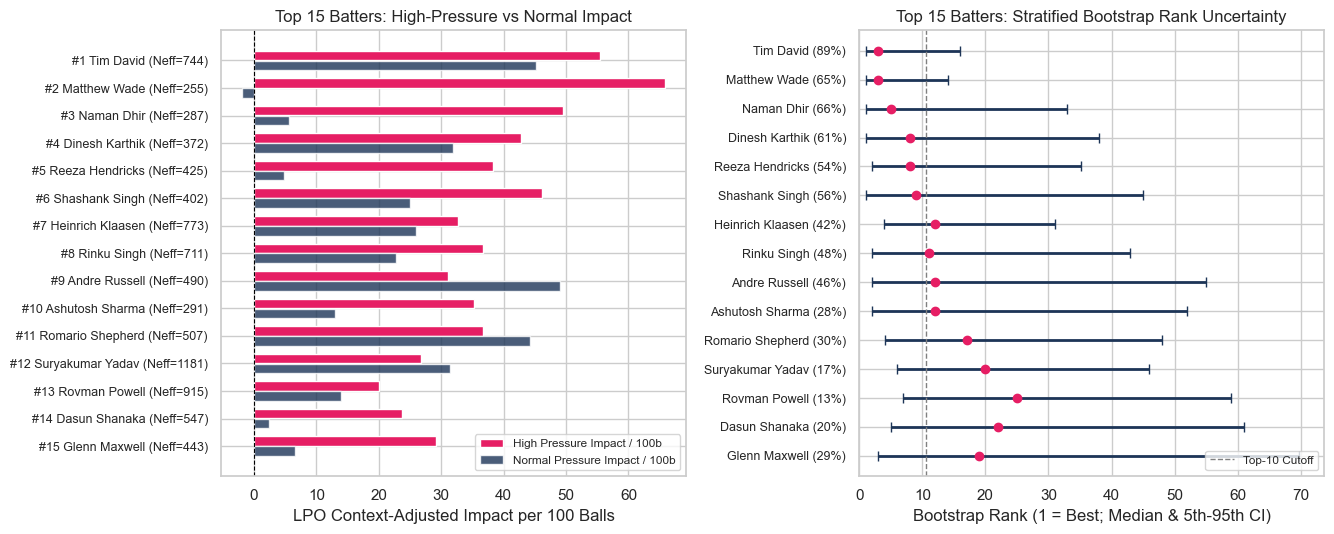

In [4]:
role_summary = (
    all_bat.groupby('primary_batting_role')
    .agg(
        n_players=('striker_id', 'count'),
        median_score=('pressure_score', 'median'),
        mean_hp_impact_100=('hp_impact_100', 'mean'),
        mean_norm_impact_100=('norm_impact_100', 'mean'),
        mean_neff=('pressure_neff', 'mean'),
        top10_count=('rank', lambda s: int((s <= 10).sum())),
    )
    .reset_index()
)
print('Eligible batters by primary batting role:')
print(role_summary.round(2).to_string(index=False))

top15 = all_bat.head(15).copy()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
y = np.arange(len(top15))[::-1]
labels = [f"#{int(r.rank)} {r.player_name} (Neff={r.pressure_neff:.0f})" for r in top15.itertuples()]
axes[0].barh(y + 0.18, top15['hp_impact_100'], height=0.35, color='#E61E64', label='High Pressure Impact / 100b')
axes[0].barh(y - 0.18, top15['norm_impact_100'], height=0.35, color='#1D3557', alpha=0.8, label='Normal Pressure Impact / 100b')
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=9)
axes[0].set_xlabel('LPO Context-Adjusted Impact per 100 Balls')
axes[0].set_title('Top 15 Batters: High-Pressure vs Normal Impact')
axes[0].legend(loc='lower right', fontsize=8.5)

# Non-inverted rank CI plot (Rank 1 on the left!)
med = top15['boot_median_rank']
err_low = np.maximum(0.0, med - top15['boot_p05_rank'])
err_high = np.maximum(0.0, top15['boot_p95_rank'] - med)
axes[1].errorbar(med, y, xerr=[err_low, err_high], fmt='o', color='#E61E64', ecolor='#1D3557', elinewidth=2, capsize=3.5)
axes[1].axvline(10.5, color='gray', linestyle='--', linewidth=1, label='Top-10 Cutoff')
axes[1].set_yticks(y)
axes[1].set_yticklabels([f"{r.player_name} ({100*r.top10_inclusion_frequency:.0f}%)" for r in top15.itertuples()], fontsize=9)
axes[1].set_xlim(0, max(60, float(top15['boot_p95_rank'].max()) + 4))
axes[1].set_xlabel('Bootstrap Rank (1 = Best; Median & 5th-95th CI)')
axes[1].set_title('Top 15 Batters: Stratified Bootstrap Rank Uncertainty')
axes[1].legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()